# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло. Він лежить в архіві демо-матеріалів лекції 3 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('torch') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'torch>=2.2,<3', '--index-url', 'https://download.pytorch.org/whl/cpu'])
packages = {
    'numpy': 'numpy>=1.26,<3', 'pandas': 'pandas>=2.2,<4',
    'matplotlib': 'matplotlib>=3.8,<4', 'seaborn': 'seaborn>=0.13,<1',
    'sklearn': 'scikit-learn>=1.4,<2', 'tensorboard': 'tensorboard>=2.16,<3',
    'gradio': 'gradio>=5,<7', 'IPython': 'ipython>=8',
}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import copy
import hashlib
import json
import math
import os
import random
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from torch.utils.tensorboard import SummaryWriter
from IPython.display import display, Markdown, IFrame

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
torch.set_num_threads(min(2, os.cpu_count() or 1))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ARTIFACT_DIR = Path('/content/drive/MyDrive/ai_systems/lab2')
else:
    ARTIFACT_DIR = Path.cwd() if Path.cwd().name == 'lab2' else Path.cwd() / 'lab2'
MODELS_DIR = ARTIFACT_DIR / 'models'
RUNS_DIR = ARTIFACT_DIR / 'runs'
DATA_DIR = ARTIFACT_DIR / 'data'
for folder in [MODELS_DIR, RUNS_DIR, DATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__, '| пристрій:', device)
print('Артефакти:', ARTIFACT_DIR)


Mounted at /content/drive
Python: 3.13.18
PyTorch: 2.11.0+cpu | пристрій: cpu
Артефакти: /content/drive/MyDrive/ai_systems/lab2


## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1 Мої відповіді:

1. kNN враховує залежність між ознаками: пропуск оцінюється за схожими
   спостереженнями, а не одним середнім для всіх рядків. Моделі імпутації
   потрібно навчати лише на train; числові ознаки для пошуку сусідів варто
   масштабувати. У наданому демо `knn_cols_no_nan` складається тільки з
   `MedHouseVal`: значення таргету використовується для відновлення ознак.
   Це витік цільової змінної, бо під час реального прогнозування її немає.
   У цій роботі пропусків немає, тому імпутація не застосовується.

2. MSE — диференційовна функція втрат для регресії, яка сильніше штрафує
   великі помилки. Однакова метрика на train і validation дозволяє порівнювати
   криві навчання. Після навчання RMSE показує помилку в одиницях таргету,
   MAE менше залежить від великих відхилень, R² порівнює якість із константним
   прогнозом. RMSE монотонно залежить від MSE, тому на одному наборі даних
   дає однакове ранжування моделей. У розділі 2.2 виконано експеримент із
   MSELoss, L1Loss та SmoothL1Loss: однакові дані, початкові ваги, SGD,
   learning rate і кількість епох; змінюється лише функція втрат. Результати
   та висновок виводяться під таблицею цього експерименту.

3. Після виконання 2.6 найбільша за модулем вага належить `MedInc`
   (+0.8271), далі `diag_coord` (−0.3044), `bedperroom` (+0.1978),
   `HouseAge` (+0.1380). Для `Population` вага близька до нуля (−0.0018).
   Інженерні ознаки мають помітні ваги, але сама вага не доводить, що
   їх додавання поліпшило якість: для цього потрібне порівняння моделей
   із ними та без них. Коефіцієнт описує зміну прогнозу за збільшення
   стандартизованої ознаки на одиницю при фіксованих інших ознаках.
   Тому знак `bedperroom` може відрізнятися від знака її парної кореляції.
   Кореляція ознак і коефіцієнти регресії не доводять причинного впливу.

4. Простий baseline для лінійної регресії — прогнозувати середнє значення
   таргету train: $\hat y=\frac{1}{n_{train}}\sum y_i$ для всіх val/test.
   У формулі R² знаменник використовує середнє саме оцінюваної вибірки,
   тому R² прогнозу середнього train на test може бути трохи від'ємним.
   Для нейромережі baseline — вже навчена множинна лінійна регресія на
   тих самих сплітах із тим самим препроцесингом і метриками.

5. Нижче побудовано графіки всіх чотирьох функцій із розділу 3.2 демо:
   ReLU, Leaky ReLU, Sigmoid і Tanh. Використано 1000 випадкових значень
   $X\sim U(-6,6)$; перед побудовою ліній значення відсортовано.

6. Після інженерії ознак у демо залишаються 7 вхідних ознак. Для
   `Linear(a,b)` кількість параметрів дорівнює $ab+b$: ваги та зміщення.
   Архітектура $7\to64\to32\to1$ має
   $(7\cdot64+64)+(64\cdot32+32)+(32\cdot1+1)=512+2080+33=2625$
   параметрів. ReLU параметрів не додає. Лінійна модель має $7+1=8$.

7. Оптимальність 200 епох у демо не підтверджена. У виконаному запуску
   найкраща validation MSE отримана на останній, 200-й епосі: 0.3711;
   train MSE — 0.3473. За останні 20 епох validation MSE зменшилася
   приблизно на 0.0043. Помітного розходження кривих немає; навчання можна
   продовжити й обирати найкращий checkpoint за validation або застосувати
   early stopping. Значення метрик також слід оцінювати з урахуванням
   використання таргету в імпутації демо, описаного у відповіді 1.

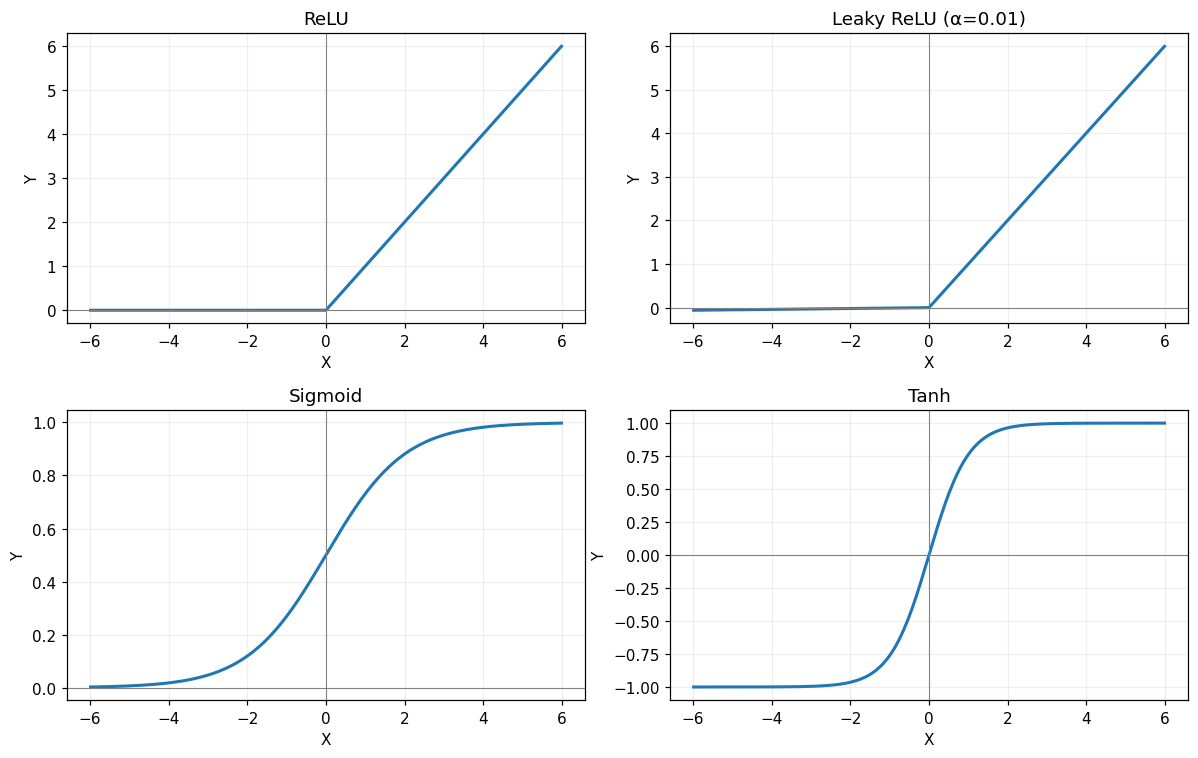

Кількість випадкових значень X: 1000


In [2]:
rng = np.random.default_rng(SEED)
activation_x = torch.tensor(np.sort(rng.uniform(-6, 6, 1000)), dtype=torch.float32)
activations = {
    'ReLU': torch.nn.ReLU(),
    'Leaky ReLU (α=0.01)': torch.nn.LeakyReLU(0.01),
    'Sigmoid': torch.nn.Sigmoid(),
    'Tanh': torch.nn.Tanh(),
}
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (name, function) in zip(axes.flat, activations.items()):
    with torch.no_grad():
        activation_y = function(activation_x)
    ax.plot(activation_x.numpy(), activation_y.numpy(), linewidth=2)
    ax.set_title(name)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.axhline(0, color='gray', linewidth=0.7)
    ax.axvline(0, color='gray', linewidth=0.7)
plt.tight_layout()
plt.show()
print('Кількість випадкових значень X:', len(activation_x))


---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [3]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Некрасов Артур Дмитрович"

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])


Ваш датасет (#5): Wine Quality


---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).
2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).
3. Загальний огляд (`head`/`info`/`describe`, 1.4).
4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.
5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?
6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).
7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.

In [4]:
assert DATASETS[dataset_index] == 'Wine Quality'
DATASET_REVISION = 'a90690dd91e947252ac664b495fb043ca545da23'
DATASET_URL = f'https://huggingface.co/datasets/codesignal/wine-quality/resolve/{DATASET_REVISION}'
DATASET_PATH = DATA_DIR / 'wine_quality.csv'
if not DATASET_PATH.exists():
    frames = []
    for wine_type, label in enumerate(['red', 'white']):
        csv_path = DATA_DIR / f'winequality-{label}.csv'
        urllib.request.urlretrieve(f'{DATASET_URL}/winequality-{label}.csv', csv_path)
        frame = pd.read_csv(csv_path, sep=';')
        frame['wine_type'] = wine_type
        frames.append(frame)
    pd.concat(frames, ignore_index=True).to_csv(DATASET_PATH, index=False)
wine_df = pd.read_csv(DATASET_PATH)
TARGET = 'quality'
raw_feature_cols = [column for column in wine_df.columns if column != TARGET]
groups = pd.util.hash_pandas_object(wine_df[raw_feature_cols], index=False).to_numpy()
train_ids, remaining_ids = next(GroupShuffleSplit(n_splits=1, train_size=0.6,
    random_state=SEED).split(wine_df, groups=groups))
val_relative, test_relative = next(GroupShuffleSplit(n_splits=1, test_size=0.5,
    random_state=SEED).split(wine_df.iloc[remaining_ids], groups=groups[remaining_ids]))
val_ids = remaining_ids[val_relative]
test_ids = remaining_ids[test_relative]
train_df = wine_df.iloc[train_ids].copy()
val_df = wine_df.iloc[val_ids].copy()
test_df = wine_df.iloc[test_ids].copy()
assert not set(groups[train_ids]) & set(groups[val_ids])
assert not set(groups[train_ids]) & set(groups[test_ids])
assert not set(groups[val_ids]) & set(groups[test_ids])
print('Джерело: codesignal/wine-quality')
print('Тип вина: 0 — червоне; 1 — біле')
print('Усього:', len(wine_df))
print(f'train / val / test: {len(train_df)} / {len(val_df)} / {len(test_df)}')
print('Перетин груп між сплітами: 0')
split_table = pd.DataFrame({'row_id': np.concatenate([train_ids, val_ids, test_ids]),
    'split': ['train'] * len(train_ids) + ['val'] * len(val_ids) + ['test'] * len(test_ids)})
split_table.to_csv(DATA_DIR / 'split_indices.csv', index=False)


Джерело: codesignal/wine-quality
Тип вина: 0 — червоне; 1 — біле
Усього: 6497
train / val / test: 3923 / 1273 / 1301
Перетин груп між сплітами: 0


Спліт виконано до EDA та обчислення будь-яких статистик. Однакові набори
хімічних ознак і типу вина належать одному спліту; для формування груп
таргет не використовується. Частки груп — 60/20/20, тому частки рядків
можуть трохи відрізнятися. Усі рішення EDA, логарифмування та статистики
StandardScaler визначаються тільки за train. Validation використовується
для вибору checkpoint та архітектури, test — після завершення експериментів.

In [5]:
display(train_df.head())
train_df.info()
display(train_df.describe().round(3))
missing_table = train_df.isna().sum().rename('missing').to_frame()
display(missing_table)
print('Пропусків у train:', int(missing_table['missing'].sum()))


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


<class 'pandas.core.frame.DataFrame'>
Index: 3923 entries, 0 to 6495
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         3923 non-null   float64
 1   volatile acidity      3923 non-null   float64
 2   citric acid           3923 non-null   float64
 3   residual sugar        3923 non-null   float64
 4   chlorides             3923 non-null   float64
 5   free sulfur dioxide   3923 non-null   float64
 6   total sulfur dioxide  3923 non-null   float64
 7   density               3923 non-null   float64
 8   pH                    3923 non-null   float64
 9   sulphates             3923 non-null   float64
 10  alcohol               3923 non-null   float64
 11  quality               3923 non-null   int64  
 12  wine_type             3923 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 429.1 KB


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
count,3923.000,3923.000,3923.000,3923.000,3923.000,3923.000,3923.000,3923.000,3923.000,3923.000,3923.000,3923.000,3923.000
mean,7.243,0.340,0.320,5.540,0.056,30.326,115.516,0.995,3.218,0.531,10.471,5.789,0.748
std,1.299,0.163,0.146,4.892,0.035,17.845,57.002,0.003,0.160,0.148,1.181,0.869,0.434
min,3.800,0.080,0.000,0.600,0.012,1.000,6.000,0.987,2.720,0.220,8.000,3.000,0.000
25%,6.500,0.230,0.250,1.800,0.038,17.000,76.500,0.992,3.110,0.430,9.500,5.000,0.000
50%,7.000,0.290,0.310,3.000,0.048,29.000,118.000,0.995,3.210,0.510,10.300,6.000,1.000
75%,7.700,0.400,0.390,8.200,0.065,41.000,156.000,0.997,3.320,0.600,11.300,6.000,1.000
max,15.600,1.330,1.660,65.800,0.610,289.000,440.000,1.039,3.900,2.000,14.200,9.000,1.000


,missing
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Пропусків у train: 0


У train немає пропусків; імпутація та видалення рядків через NaN не потрібні.
Вхід містить 11 числових хімічних показників і бінарну ознаку `wine_type`.
`quality` — дискретна оцінка, яку тут прогнозуємо як числовий таргет регресії.

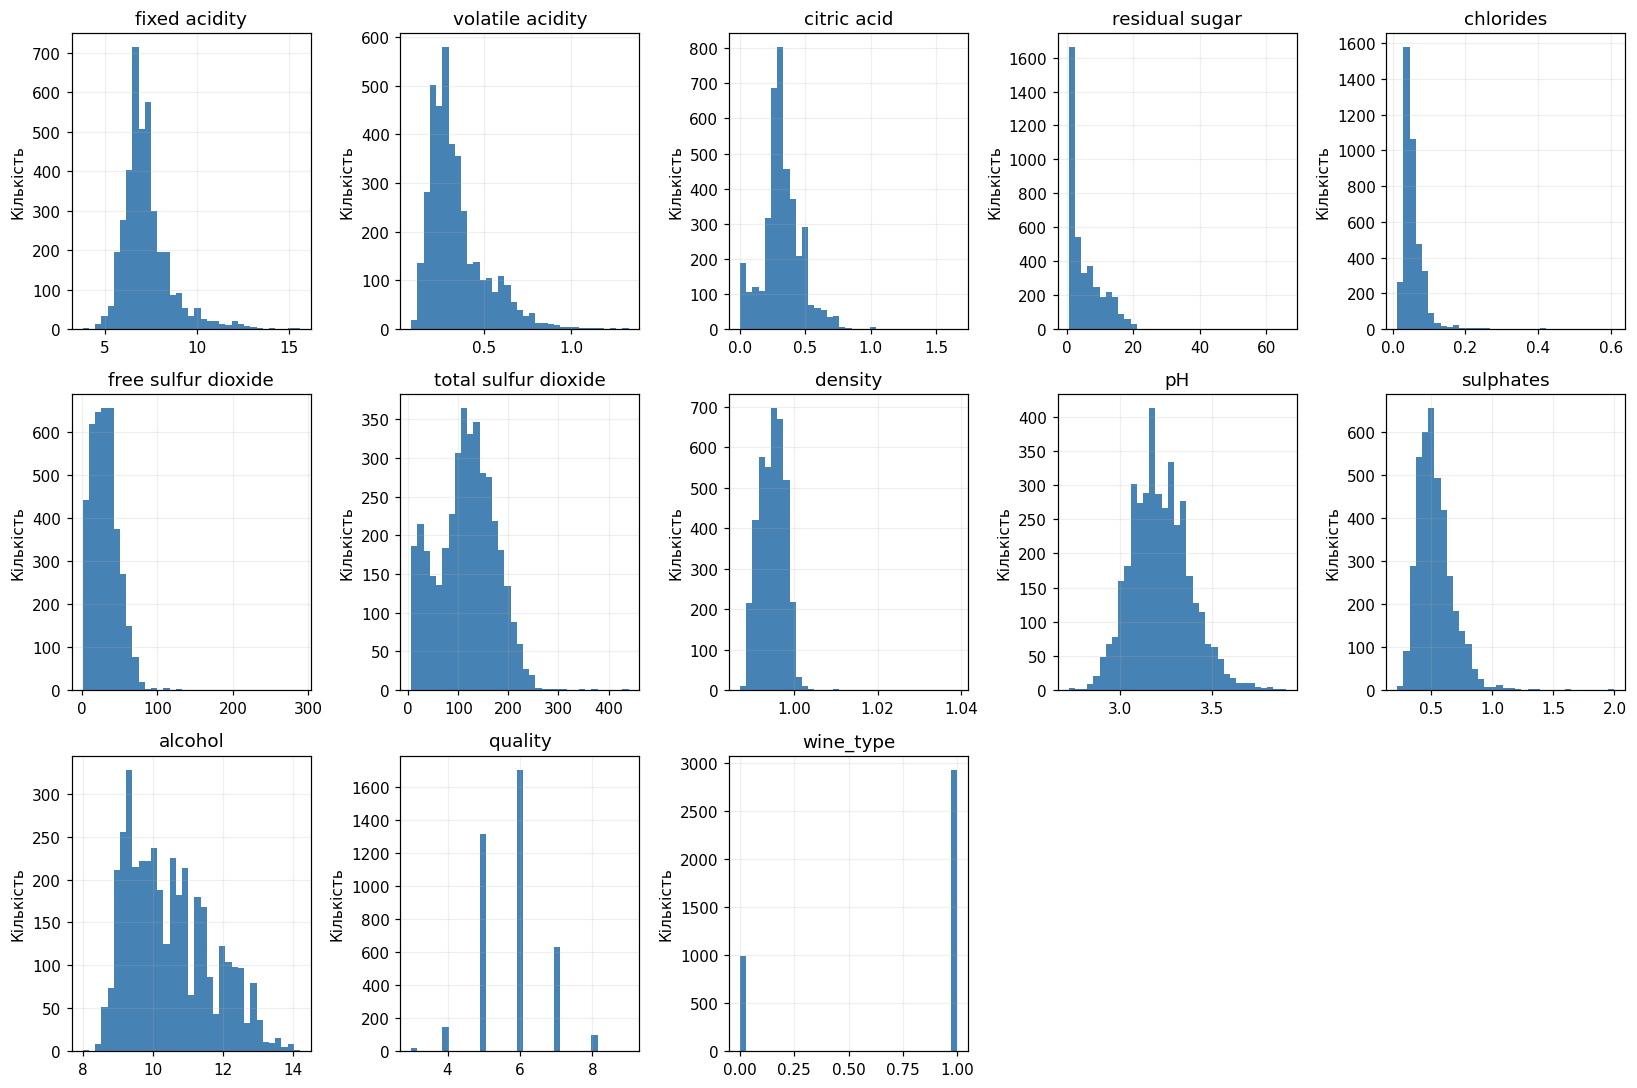

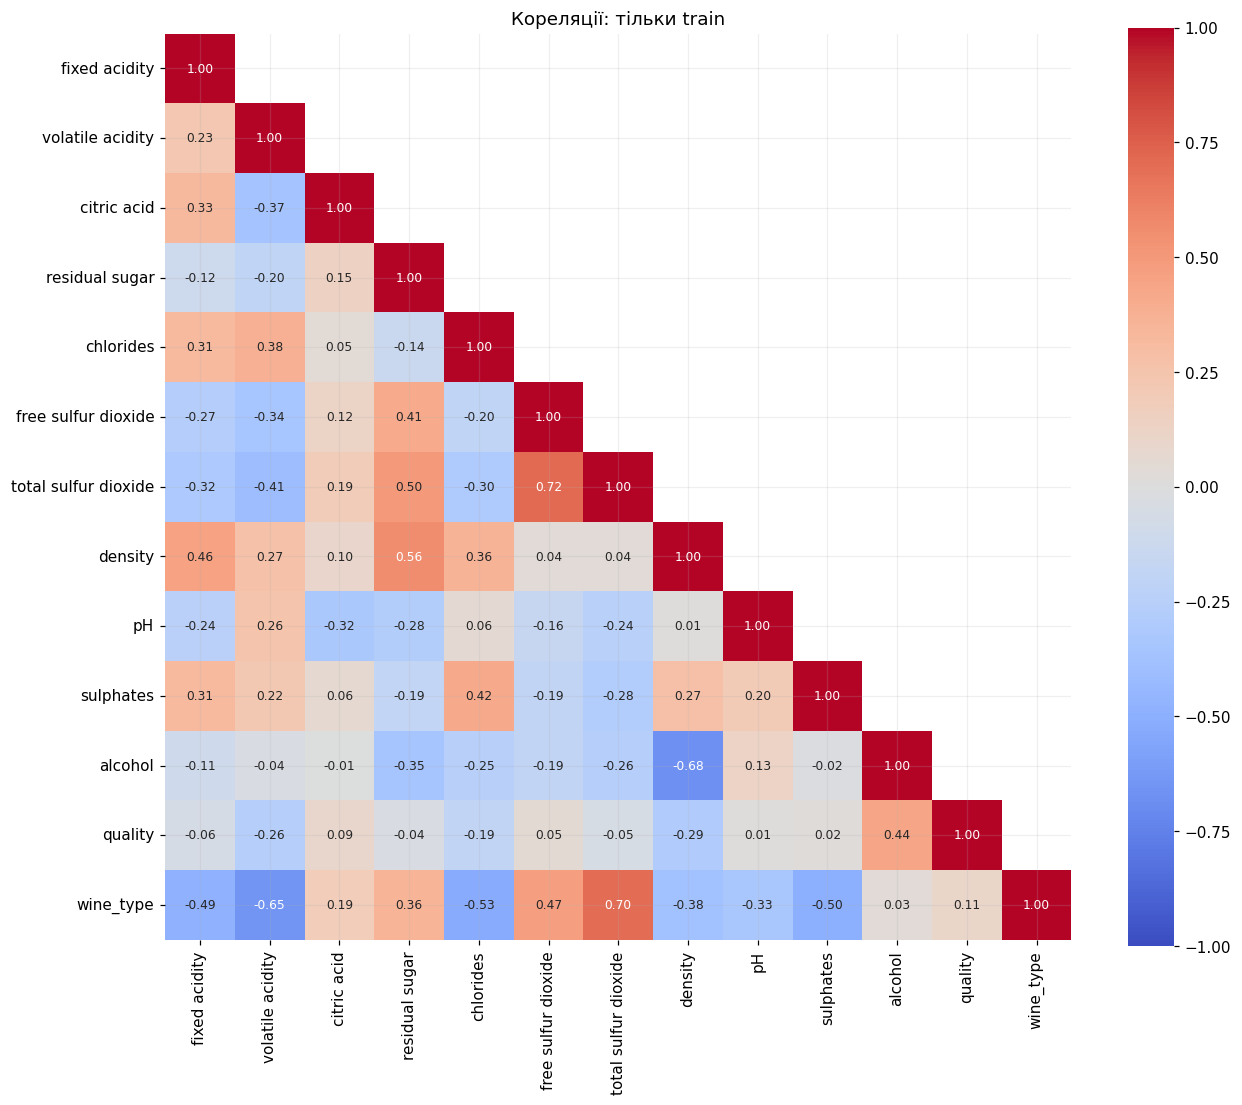

,correlation
alcohol,0.442361
wine_type,0.105579
citric acid,0.089315
free sulfur dioxide,0.047431
sulphates,0.022783
pH,0.011576
residual sugar,-0.038352
total sulfur dioxide,-0.050301
fixed acidity,-0.061723
chlorides,-0.190632


,skewness
chlorides,5.522686
sulphates,1.773344
fixed acidity,1.749906
residual sugar,1.552524
volatile acidity,1.499122
free sulfur dioxide,1.413651
density,0.790362
alcohol,0.570661
citric acid,0.523937
pH,0.392761


In [6]:
hist_axes = train_df.hist(bins=35, figsize=(15, 10), layout=(3, 5), color='steelblue')
for ax in hist_axes.flat:
    if ax.has_data():
        ax.set_ylabel('Кількість')
plt.tight_layout()
plt.show()

train_correlation = train_df.corr(numeric_only=True)
plt.figure(figsize=(12, 10))
sns.heatmap(train_correlation, mask=np.triu(np.ones_like(train_correlation, dtype=bool), 1),
            annot=True, fmt='.2f', annot_kws={'size': 8}, cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True)
plt.title('Кореляції: тільки train')
plt.tight_layout()
plt.show()
display(train_correlation[TARGET].drop(TARGET).sort_values(ascending=False).rename('correlation'))
display(train_df[raw_feature_cols].skew().sort_values(ascending=False).rename('skewness'))


Найпомітніший додатний лінійний зв'язок із quality має alcohol
(приблизно +0.44), від'ємні — density (−0.29) та volatile acidity (−0.26).
Розподіл quality зосереджений біля 5–6, крайні оцінки рідкісні. Це
обмежена шкала оцінювання; піку на верхній межі, подібного до capping
MedHouseVal у демо, на гістограмі немає. Найдовший правий хвіст має
chlorides; помітно скошені також fixed acidity, residual sugar та sulphates.
Є кореляції між density, residual sugar й alcohol, а також між показниками
діоксиду сірки. Низька парна кореляція з quality не є достатньою причиною
видаляти ознаку: залежність може бути нелінійною або залежати від типу вина.

In [7]:
continuous_cols = [column for column in raw_feature_cols if column != 'wine_type']
q1 = train_df[continuous_cols].quantile(0.25)
q3 = train_df[continuous_cols].quantile(0.75)
iqr = q3 - q1
outlier_counts = ((train_df[continuous_cols] < q1 - 1.5 * iqr) |
                  (train_df[continuous_cols] > q3 + 1.5 * iqr)).sum()
display(outlier_counts.sort_values(ascending=False).rename('outside_1.5_IQR').to_frame())
print('Нескінченних значень у train:', int(np.isinf(train_df.to_numpy()).sum()))
print('Від’ємних хімічних показників у train:', int((train_df[continuous_cols] < 0).sum().sum()))
log_columns = [column for column in continuous_cols
               if train_df[column].min() >= 0 and train_df[column].skew() > 1]
print('Ознаки для log1p:', log_columns)


,outside_1.5_IQR
citric acid,313
fixed acidity,231
volatile acidity,216
chlorides,166
sulphates,101
residual sugar,76
pH,50
free sulfur dioxide,31
total sulfur dioxide,8
density,3


Нескінченних значень у train: 0
Від’ємних хімічних показників у train: 0
Ознаки для log1p: ['fixed acidity', 'volatile acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'sulphates']


Межі 1.5 IQR позначають рідкісні значення, але самі по собі не доводять
помилку вимірювання. Нескінченних і від'ємних хімічних показників немає;
підстав видаляти всі рідкісні зразки немає. Рядки залишено, скошені
невід'ємні ознаки зі skewness > 1 на train перетворено через log1p.
Таргет не обрізається й не логарифмується.

Додано `free_sulfur_fraction`: співвідношення вільного до загального
діоксиду сірки. Воно описує відносний склад і розраховується однаково
для всіх сплітів. Початкові показники залишено: абсолютна кількість
і співвідношення несуть різну інформацію. Інші корельовані ознаки також
залишено; сам факт кореляції не означає повного дублювання.

In [8]:
def engineer_features(frame, log_features):
    result = frame[raw_feature_cols].copy()
    result['free_sulfur_fraction'] = (result['free sulfur dioxide'] /
                                      result['total sulfur dioxide'].clip(lower=1e-6))
    for column in log_features:
        result[column] = np.log1p(result[column])
    return result.rename(columns={column: f'log1p({column})' for column in log_features})

train_features = engineer_features(train_df, log_columns)
val_features = engineer_features(val_df, log_columns)
test_features = engineer_features(test_df, log_columns)
feature_cols = list(train_features.columns)
scaler = StandardScaler()
X_train = scaler.fit_transform(train_features).astype(np.float32)
X_val = scaler.transform(val_features).astype(np.float32)
X_test = scaler.transform(test_features).astype(np.float32)
y_train = train_df[TARGET].to_numpy(dtype=np.float32)
y_val = val_df[TARGET].to_numpy(dtype=np.float32)
y_test = test_df[TARGET].to_numpy(dtype=np.float32)

def to_tensor(X, y):
    return (torch.tensor(X, dtype=torch.float32, device=device),
            torch.tensor(y, dtype=torch.float32, device=device).reshape(-1, 1))

x_train_t, y_train_t = to_tensor(X_train, y_train)
x_val_t, y_val_t = to_tensor(X_val, y_val)
x_test_t, y_test_t = to_tensor(X_test, y_test)
n_features = X_train.shape[1]
preprocessor = {'raw_features': raw_feature_cols, 'feature_names': feature_cols,
    'log_columns': log_columns, 'mean': torch.tensor(scaler.mean_),
    'scale': torch.tensor(scaler.scale_)}
print('Форми тензорів:', tuple(x_train_t.shape), tuple(x_val_t.shape), tuple(x_test_t.shape))
print('Кількість ознак:', n_features)
display(train_features.head())


Форми тензорів: (3923, 13) (1273, 13) (1301, 13)
Кількість ознак: 13


,log1p(fixed acidity),log1p(volatile acidity),citric acid,log1p(residual sugar),log1p(chlorides),log1p(free sulfur dioxide),total sulfur dioxide,density,pH,log1p(sulphates),alcohol,wine_type,free_sulfur_fraction
0,2.128232,0.530628,0.00,1.064711,0.073250,2.484907,34.0,0.9978,3.51,0.444686,9.4,0,0.323529
1,2.174752,0.631272,0.00,1.280934,0.093490,3.258097,67.0,0.9968,3.20,0.518794,9.8,0,0.373134
2,2.174752,0.565314,0.04,1.193922,0.088011,2.772589,54.0,0.9970,3.26,0.500775,9.8,0,0.277778
3,2.501436,0.246860,0.56,1.064711,0.072321,2.890372,60.0,0.9980,3.16,0.457425,9.8,0,0.283333
4,2.128232,0.530628,0.00,1.064711,0.073250,2.484907,34.0,0.9978,3.51,0.444686,9.4,0,0.323529


### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.

In [9]:
def build_model(input_size, hidden_sizes, activation='ReLU'):
    if not hidden_sizes:
        return torch.nn.Linear(input_size, 1)
    layers = []
    previous = input_size
    activation_class = {'ReLU': torch.nn.ReLU, 'Tanh': torch.nn.Tanh,
                        'LeakyReLU': torch.nn.LeakyReLU}[activation]
    for width in hidden_sizes:
        layers.extend([torch.nn.Linear(previous, width), activation_class()])
        previous = width
    layers.append(torch.nn.Linear(previous, 1))
    return torch.nn.Sequential(*layers)


def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE': float(mse), 'RMSE': float(np.sqrt(mse)),
            'MAE': float(mean_absolute_error(y_true, y_pred)),
            'R2': float(r2_score(y_true, y_pred))}


records = {}
histories = {}
trained_models = {}


def train_variant(name, config):
    set_seed()
    model = build_model(n_features, config['hidden_sizes'], config['activation']).to(device)
    optimizer_class = {'Adam': torch.optim.Adam, 'SGD': torch.optim.SGD}[config['optimizer']]
    optimizer = optimizer_class(model.parameters(), lr=config['lr'])
    objective = {'MSE': torch.nn.MSELoss(), 'MAE': torch.nn.L1Loss(),
                 'Huber': torch.nn.SmoothL1Loss(beta=1.0)}[config['loss']]
    writer = SummaryWriter(log_dir=str(RUNS_DIR / name), purge_step=0)
    best_val = float('inf')
    best_epoch = 0
    best_state = None
    history = []
    try:
        for epoch in range(1, config['epochs'] + 1):
            model.train()
            optimizer.zero_grad()
            loss = objective(model(x_train_t), y_train_t)
            loss.backward()
            optimizer.step()
            model.eval()
            with torch.no_grad():
                train_prediction = model(x_train_t)
                val_prediction = model(x_val_t)
                train_mse = torch.mean((train_prediction - y_train_t) ** 2).item()
                val_mse = torch.mean((val_prediction - y_val_t) ** 2).item()
                val_mae = torch.mean(torch.abs(val_prediction - y_val_t)).item()
            history.append({'epoch': epoch, 'train_mse': train_mse,
                            'val_mse': val_mse, 'objective': loss.item()})
            writer.add_scalar('Loss/train', train_mse, epoch)
            writer.add_scalar('Loss/val', val_mse, epoch)
            writer.add_scalar('MAE/val', val_mae, epoch)
            writer.add_scalar('Objective/train', loss.item(), epoch)
            if val_mse < best_val:
                best_val, best_epoch = val_mse, epoch
                best_state = {key: value.detach().cpu().clone()
                              for key, value in model.state_dict().items()}
            if epoch in [1, 100, 200, 400, config['epochs']]:
                print(f'{name}: epoch={epoch:3d}; train MSE={train_mse:.5f}; val MSE={val_mse:.5f}')
    finally:
        writer.close()
    model.load_state_dict(best_state)
    model.eval()
    checkpoint = {'state_dict': best_state, 'config': dict(config),
                  'n_features': n_features, 'preprocessor': preprocessor,
                  'best_epoch': best_epoch, 'val_MSE': best_val,
                  'target': TARGET, 'seed': SEED, 'dataset': 'codesignal/wine-quality'}
    torch.save(checkpoint, MODELS_DIR / f'{name}.pt')
    records[name] = {'model': name, 'val_MSE': best_val, 'best_epoch': best_epoch,
                     'parameters': sum(p.numel() for p in model.parameters()),
                     'config': dict(config)}
    histories[name] = pd.DataFrame(history)
    histories[name].to_csv(RUNS_DIR / name / 'history.csv', index=False)
    trained_models[name] = model
    return model


linear_config = {'hidden_sizes': [], 'activation': 'ReLU', 'optimizer': 'SGD',
                 'lr': 0.03, 'epochs': 400, 'loss': 'MSE'}
linear_model = train_variant('linear', linear_config)
mean_prediction = np.full(y_val.shape, y_train.mean(), dtype=np.float32)
display(pd.DataFrame([regression_metrics(y_val, mean_prediction)], index=['mean_train: validation']).round(5))


linear: epoch=  1; train MSE=30.16388; val MSE=31.34268
linear: epoch=100; train MSE=0.53178; val MSE=0.55798
linear: epoch=200; train MSE=0.52759; val MSE=0.55266
linear: epoch=400; train MSE=0.52620; val MSE=0.55110


,MSE,RMSE,MAE,R2
mean_train: validation,0.81986,0.90546,0.70312,-0.01269


,feature,weight_standardized
10,alcohol,0.34921
1,log1p(volatile acidity),-0.24629
5,log1p(free sulfur dioxide),0.18478
3,log1p(residual sugar),0.16861
6,total sulfur dioxide,-0.15892
11,wine_type,-0.11171
7,density,-0.10214
9,log1p(sulphates),0.08115
0,log1p(fixed acidity),0.05635
4,log1p(chlorides),-0.03079


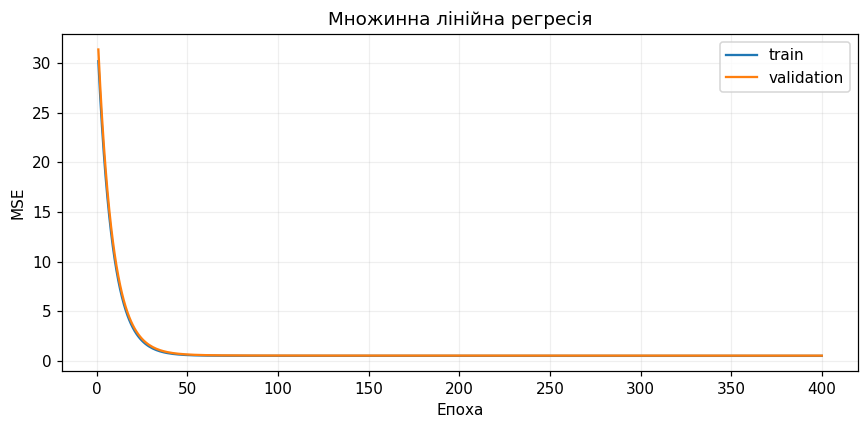

In [10]:
linear_weights = linear_model.weight.detach().cpu().numpy().ravel()
weight_table = pd.DataFrame({'feature': feature_cols, 'weight_standardized': linear_weights})
weight_table = weight_table.assign(abs_weight=weight_table['weight_standardized'].abs()).sort_values(
    'abs_weight', ascending=False).drop(columns='abs_weight')
display(weight_table.round(5))
linear_history = histories['linear']
plt.figure(figsize=(8, 4))
plt.plot(linear_history['epoch'], linear_history['train_mse'], label='train')
plt.plot(linear_history['epoch'], linear_history['val_mse'], label='validation')
plt.xlabel('Епоха')
plt.ylabel('MSE')
plt.title('Множинна лінійна регресія')
plt.legend()
plt.tight_layout()
plt.show()


Ваги відповідають стандартизованим ознакам; для log1p-ознак — після
логарифмування. Кожен коефіцієнт описує зміну прогнозованої якості при
збільшенні відповідної перетвореної ознаки на одне стандартне відхилення
train за фіксованих інших входів. За корельованих ознак розподіл ваг між
ними може бути нестійким; це не оцінка причинного впливу.

In [11]:
for name, loss_name in [('linear_mae', 'MAE'), ('linear_huber', 'Huber')]:
    config = dict(linear_config)
    config['loss'] = loss_name
    train_variant(name, config)

loss_rows = []
for name in ['linear', 'linear_mae', 'linear_huber']:
    with torch.no_grad():
        prediction = trained_models[name](x_val_t).cpu().numpy().ravel()
    loss_rows.append({'model': name, 'loss': records[name]['config']['loss'],
                     **regression_metrics(y_val, prediction)})
loss_comparison = pd.DataFrame(loss_rows)
display(loss_comparison.round(5))
best_mse_loss = loss_comparison.loc[loss_comparison['MSE'].idxmin()]
best_mae_loss = loss_comparison.loc[loss_comparison['MAE'].idxmin()]
display(Markdown(f"**Відповідь 0.1.2 — результат експерименту.** "
    f"Найменша validation MSE: **{best_mse_loss['loss']}** "
    f"({best_mse_loss['MSE']:.5f}); найменша validation MAE: "
    f"**{best_mae_loss['loss']}** ({best_mae_loss['MAE']:.5f}). "
    "Функції втрат по-різному штрафують великі відхилення, тому одна й та сама "
    "модель може мати різне ранжування за MSE та MAE. Checkpoint кожного "
    "варіанта обрано за validation MSE; test у цьому експерименті не використано."))


linear_mae: epoch=  1; train MSE=33.78156; val MSE=35.10925
linear_mae: epoch=100; train MSE=8.60363; val MSE=9.26655
linear_mae: epoch=200; train MSE=0.71050; val MSE=0.78528
linear_mae: epoch=400; train MSE=0.53313; val MSE=0.55971
linear_huber: epoch=  1; train MSE=33.78156; val MSE=35.10925
linear_huber: epoch=100; train MSE=8.61018; val MSE=9.27250
linear_huber: epoch=200; train MSE=0.80425; val MSE=0.89862
linear_huber: epoch=400; train MSE=0.53228; val MSE=0.55610


,model,loss,MSE,RMSE,MAE,R2
0,linear,MSE,0.55110,0.74236,0.56836,0.31928
1,linear_mae,MAE,0.55971,0.74814,0.56747,0.30865
2,linear_huber,Huber,0.55610,0.74572,0.56744,0.31310


**Відповідь 0.1.2 — результат експерименту.** Найменша validation MSE: **MSE** (0.55110); найменша validation MAE: **Huber** (0.56744). Функції втрат по-різному штрафують великі відхилення, тому одна й та сама модель може мати різне ранжування за MSE та MAE. Checkpoint кожного варіанта обрано за validation MSE; test у цьому експерименті не використано.

### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.

In [12]:
nn_configs = {
    'nn_v1': {'hidden_sizes': [32], 'activation': 'ReLU', 'optimizer': 'Adam',
              'lr': 0.003, 'epochs': 400, 'loss': 'MSE'},
    'nn_v2': {'hidden_sizes': [64, 32], 'activation': 'ReLU', 'optimizer': 'Adam',
              'lr': 0.003, 'epochs': 400, 'loss': 'MSE'},
}
for name, config in nn_configs.items():
    architecture = build_model(n_features, config['hidden_sizes'], config['activation'])
    print(name, architecture)
    print('Кількість параметрів:', sum(p.numel() for p in architecture.parameters()))
    train_variant(name, config)
best_architecture_name = min(nn_configs, key=lambda name: records[name]['val_MSE'])
best_architecture_config = dict(nn_configs[best_architecture_name])
print('Краща архітектура за validation MSE:', best_architecture_name)


nn_v1 Sequential(
  (0): Linear(in_features=13, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів: 481
nn_v1: epoch=  1; train MSE=32.61627; val MSE=33.69431
nn_v1: epoch=100; train MSE=1.59530; val MSE=1.67473
nn_v1: epoch=200; train MSE=1.02077; val MSE=1.08120
nn_v1: epoch=400; train MSE=0.60764; val MSE=0.67704
nn_v2 Sequential(
  (0): Linear(in_features=13, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів: 3009
nn_v2: epoch=  1; train MSE=33.34370; val MSE=34.51798
nn_v2: epoch=100; train MSE=0.90055; val MSE=0.95035
nn_v2: epoch=200; train MSE=0.60552; val MSE=0.66052
nn_v2: epoch=400; train MSE=0.48402; val MSE=0.55508
Краща архітектура за validation MSE: nn_v2


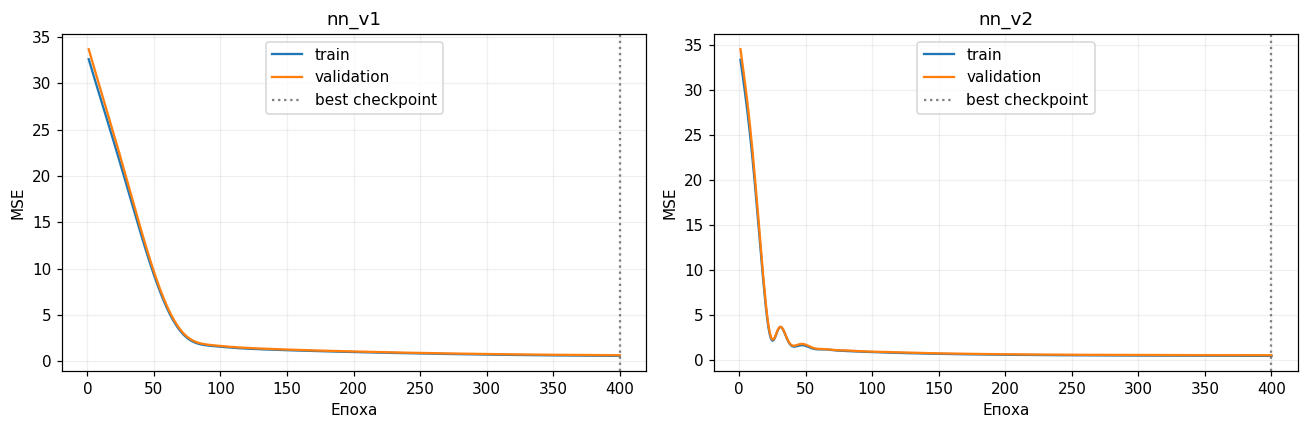

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, nn_configs):
    frame = histories[name]
    ax.plot(frame['epoch'], frame['train_mse'], label='train')
    ax.plot(frame['epoch'], frame['val_mse'], label='validation')
    ax.axvline(records[name]['best_epoch'], color='gray', linestyle=':', label='best checkpoint')
    ax.set_title(name)
    ax.set_xlabel('Епоха')
    ax.set_ylabel('MSE')
    ax.legend()
plt.tight_layout()
plt.show()


### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.

In [14]:
tuning_changes = {
    'nn_best_lr_0.001': {'lr': 0.001},
    'nn_best_sgd': {'optimizer': 'SGD'},
    'nn_best_epochs_800': {'epochs': 800},
}
for name, change in tuning_changes.items():
    config = dict(best_architecture_config)
    config.update(change)
    assert sum(config[key] != best_architecture_config[key] for key in config) == 1
    train_variant(name, config)
tuning_rows = []
for name in [best_architecture_name, *tuning_changes]:
    record = records[name]
    tuning_rows.append({'model': name, 'hidden_sizes': str(record['config']['hidden_sizes']),
        'optimizer': record['config']['optimizer'], 'lr': record['config']['lr'],
        'epochs': record['config']['epochs'], 'best_epoch': record['best_epoch'],
        'val_MSE': record['val_MSE']})
tuning_table = pd.DataFrame(tuning_rows)
display(tuning_table.round(5))
recommended_model = min(records, key=lambda name: records[name]['val_MSE'])
print('Модель, обрана до перевірки test:', recommended_model)


nn_best_lr_0.001: epoch=  1; train MSE=34.04855; val MSE=35.23903
nn_best_lr_0.001: epoch=100; train MSE=1.51319; val MSE=1.61878
nn_best_lr_0.001: epoch=200; train MSE=1.01860; val MSE=1.06853
nn_best_lr_0.001: epoch=400; train MSE=0.66778; val MSE=0.72179
nn_best_sgd: epoch=  1; train MSE=33.45698; val MSE=34.63440
nn_best_sgd: epoch=100; train MSE=1.01322; val MSE=1.08078
nn_best_sgd: epoch=200; train MSE=0.78408; val MSE=0.83234
nn_best_sgd: epoch=400; train MSE=0.64857; val MSE=0.69561
nn_best_epochs_800: epoch=  1; train MSE=33.34370; val MSE=34.51798
nn_best_epochs_800: epoch=100; train MSE=0.90055; val MSE=0.95035
nn_best_epochs_800: epoch=200; train MSE=0.60552; val MSE=0.66052
nn_best_epochs_800: epoch=400; train MSE=0.48402; val MSE=0.55508
nn_best_epochs_800: epoch=800; train MSE=0.43490; val MSE=0.53528


,model,hidden_sizes,optimizer,lr,epochs,best_epoch,val_MSE
0,nn_v2,"[64, 32]",Adam,0.003,400,400,0.55508
1,nn_best_lr_0.001,"[64, 32]",Adam,0.001,400,400,0.72179
2,nn_best_sgd,"[64, 32]",SGD,0.003,400,400,0.69561
3,nn_best_epochs_800,"[64, 32]",Adam,0.003,800,800,0.53528


Модель, обрана до перевірки test: nn_best_epochs_800


У кожному з трьох експериментів відносно кращої початкової архітектури
змінено тільки один параметр: learning rate, тип оптимізатора або кількість
епох. Спліт, препроцесинг, seed та решта налаштувань однакові. Усі
контрольні точки обираються за найменшою validation MSE, а не за test.

### 2.5. Логування і порівняння

Кожен варіант (2.2-2.4) логуйте в TensorBoard в окрему підпапку `RUNS_DIR` (як у 2.3/3.5 демо) — з осмисленою назвою (`linear`, `nn_v1_2layers`, `nn_v2_deeper`, `nn_v2_lr_0.001`, ...), щоб потім усі криві можна було накласти одна на одну (3.8 демо) і візуально порівняти.

Наприкінці зведіть усі варіанти в одну таблицю (модель → MSE/RMSE/MAE/R² на test) і дайте коротку письмову відповідь:
- Яка модель перемогла і наскільки суттєво?
- Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?
- Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

In [15]:
rows = []
for name, record in records.items():
    model = trained_models[name]
    with torch.no_grad():
        prediction = model(x_test_t).cpu().numpy().ravel()
    config = record['config']
    rows.append({'model': name, **regression_metrics(y_test, prediction),
        'val_MSE': record['val_MSE'], 'best_epoch': record['best_epoch'],
        'parameters': record['parameters'], 'hidden_sizes': str(config['hidden_sizes']),
        'optimizer': config['optimizer'], 'learning_rate': config['lr'],
        'epochs': config['epochs'], 'loss': config['loss']})
results = pd.DataFrame(rows).sort_values('MSE').reset_index(drop=True)
results.to_csv(ARTIFACT_DIR / 'results.csv', index=False)
display(results.round(5))
display(pd.DataFrame([regression_metrics(y_test, np.full(y_test.shape, y_train.mean(), dtype=np.float32))],
                     index=['mean_train: test']).round(5))


,model,MSE,RMSE,MAE,R2,val_MSE,best_epoch,parameters,hidden_sizes,optimizer,learning_rate,epochs,loss
0,nn_best_epochs_800,0.47367,0.68824,0.53846,0.35185,0.53528,800,3009,"[64, 32]",Adam,0.003,800,MSE
1,nn_v2,0.49400,0.70285,0.55213,0.32404,0.55508,400,3009,"[64, 32]",Adam,0.003,400,MSE
2,linear,0.51493,0.71758,0.56117,0.29540,0.55110,400,14,[],SGD,0.030,400,MSE
3,linear_huber,0.51903,0.72043,0.55991,0.28979,0.55610,400,14,[],SGD,0.030,400,Huber
4,linear_mae,0.52301,0.72320,0.55946,0.28434,0.55971,400,14,[],SGD,0.030,400,MAE
5,nn_v1,0.62006,0.78744,0.62815,0.15154,0.67704,400,481,[32],Adam,0.003,400,MSE
6,nn_best_sgd,0.65124,0.80699,0.63529,0.10888,0.69561,400,3009,"[64, 32]",SGD,0.003,400,MSE
7,nn_best_lr_0.001,0.68659,0.82861,0.65174,0.06050,0.72179,400,3009,"[64, 32]",Adam,0.001,400,MSE


,MSE,RMSE,MAE,R2
mean_train: test,0.73322,0.85628,0.68952,-0.0033


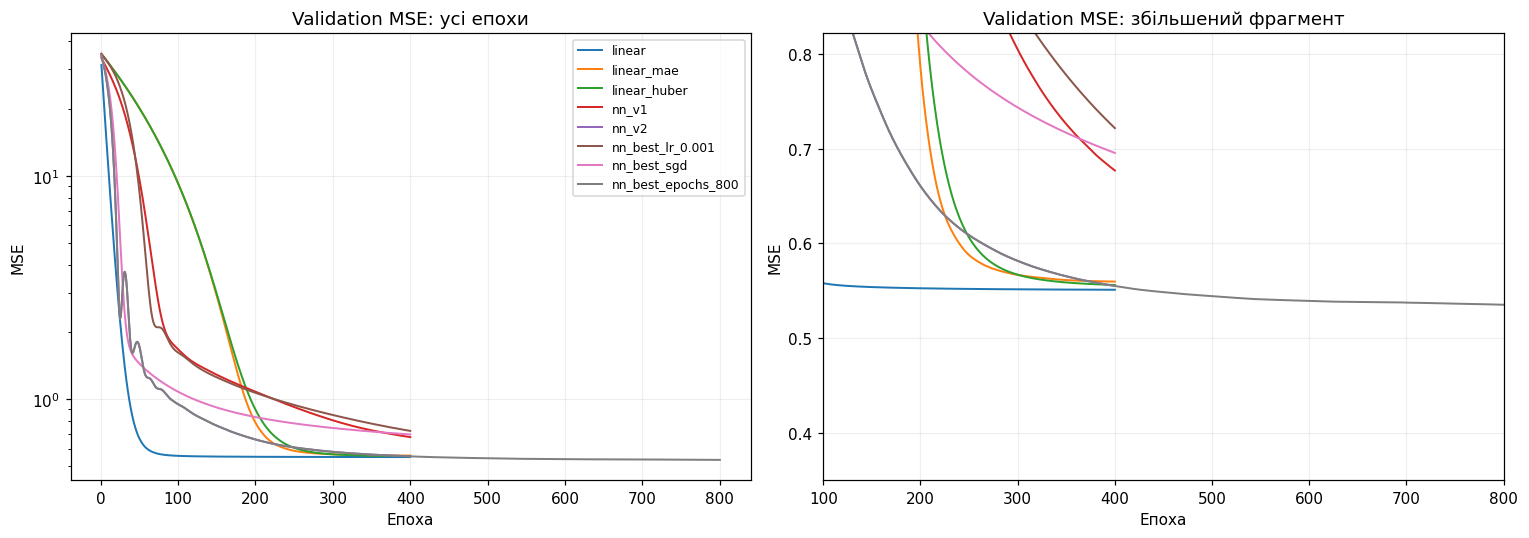

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, frame in histories.items():
    axes[0].plot(frame['epoch'], frame['val_mse'], label=name, linewidth=1.3)
    axes[1].plot(frame['epoch'], frame['val_mse'], label=name, linewidth=1.3)
axes[0].set_yscale('log')
axes[0].set_title('Validation MSE: усі епохи')
axes[1].set_xlim(100, 800)
axes[1].set_ylim(0.35, min(1.0, max(record['val_MSE'] for record in records.values()) + 0.1))
axes[1].set_title('Validation MSE: збільшений фрагмент')
for ax in axes:
    ax.set_xlabel('Епоха')
    ax.set_ylabel('MSE')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()


In [17]:
comparison = results.set_index('model')
test_winner = results.iloc[0]
linear_test_mse = float(comparison.loc['linear', 'MSE'])
winner_gain = 100 * (linear_test_mse - float(test_winner['MSE'])) / linear_test_mse
best_nn_by_val = min([name for name in records if name.startswith('nn_')],
                    key=lambda name: records[name]['val_MSE'])
nn_test_mse = float(comparison.loc[best_nn_by_val, 'MSE'])
nn_gain = 100 * (linear_test_mse - nn_test_mse) / linear_test_mse
architecture_delta = records['nn_v1']['val_MSE'] - records['nn_v2']['val_MSE']
tuning_deltas = {name: records[best_architecture_name]['val_MSE'] - records[name]['val_MSE']
                 for name in tuning_changes}
best_change = max(tuning_deltas, key=tuning_deltas.get)
worst_change = min(tuning_deltas, key=tuning_deltas.get)
effect_gains = {'архітектура nn_v1 → nn_v2': architecture_delta, **tuning_deltas}
strongest_effect = max(effect_gains, key=effect_gains.get)
nn_verdict = 'виправдала себе' if nn_gain > 0 else 'не поліпшила test MSE'
summary = (
    f"1. Найменшу test MSE має **{test_winner['model']}**: "
    f"{test_winner['MSE']:.5f}, RMSE={test_winner['RMSE']:.5f}, "
    f"MAE={test_winner['MAE']:.5f}, R²={test_winner['R2']:.5f}. "
    f"Зменшення MSE відносно лінійної регресії — {winner_gain:.2f}%.\n\n"
    f"2. Найкраща за validation нейромережа **{best_nn_by_val}** {nn_verdict}; "
    f"зміна test MSE відносно linear — {nn_gain:.2f}% у бік зменшення. "
    "Це результат одного фіксованого спліту; статистична значущість не оцінювалася.\n\n"
    f"3. Перехід nn_v1 → nn_v2 змінив validation MSE на "
    f"{architecture_delta:+.5f} у бік зменшення. Найкраща зміна гіперпараметра — "
    f"**{best_change}**: {tuning_deltas[best_change]:+.5f}; "
    f"найбільше погіршення — **{worst_change}**: {tuning_deltas[worst_change]:+.5f}. "
    "Додатна різниця означає поліпшення. "
    f"Найбільший приріст: **{strongest_effect}** ({effect_gains[strongest_effect]:+.5f}). "
    "Модель для використання обрана "
    f"за validation до оцінювання test: **{recommended_model}**."
)
display(Markdown(summary))
(ARTIFACT_DIR / 'conclusions.md').write_text(summary, encoding='utf-8')


1. Найменшу test MSE має **nn_best_epochs_800**: 0.47367, RMSE=0.68824, MAE=0.53846, R²=0.35185. Зменшення MSE відносно лінійної регресії — 8.01%.

2. Найкраща за validation нейромережа **nn_best_epochs_800** виправдала себе; зміна test MSE відносно linear — 8.01% у бік зменшення. Це результат одного фіксованого спліту; статистична значущість не оцінювалася.

3. Перехід nn_v1 → nn_v2 змінив validation MSE на +0.12196 у бік зменшення. Найкраща зміна гіперпараметра — **nn_best_epochs_800**: +0.01980; найбільше погіршення — **nn_best_lr_0.001**: -0.16671. Додатна різниця означає поліпшення. Найбільший приріст: **архітектура nn_v1 → nn_v2** (+0.12196). Модель для використання обрана за validation до оцінювання test: **nn_best_epochs_800**.

745

In [18]:
from tensorboard import program

tensorboard_instance = program.TensorBoard()
tensorboard_instance.configure(argv=['tensorboard', '--logdir', str(RUNS_DIR),
    '--host', '127.0.0.1', '--port', '0', '--load_fast', 'false'])
tensorboard_url = tensorboard_instance.launch()
print('TensorBoard:', tensorboard_url)
if IN_COLAB:
    from google.colab import output
    from urllib.parse import urlparse
    output.serve_kernel_port_as_iframe(urlparse(tensorboard_url).port, height=650)
else:
    display(IFrame(tensorboard_url, width='100%', height=650))


TensorBoard: http://127.0.0.1:41505/


<IPython.core.display.Javascript object>

---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

In [19]:
import gradio as gr

loaded_models = {}
loaded_checkpoints = {}
for name in records:
    checkpoint = torch.load(MODELS_DIR / f'{name}.pt', weights_only=True, map_location='cpu')
    config = checkpoint['config']
    model = build_model(checkpoint['n_features'], config['hidden_sizes'], config['activation'])
    model.load_state_dict(checkpoint['state_dict'])
    model.eval()
    loaded_models[name] = model
    loaded_checkpoints[name] = checkpoint

reload_differences = []
with torch.no_grad():
    for name, model in loaded_models.items():
        reloaded = model(torch.tensor(X_test))
        original_prediction = trained_models[name](x_test_t).cpu()
        difference = (reloaded - original_prediction).abs().max().item()
        reload_differences.append({'model': name, 'max_prediction_difference': difference})
        assert torch.allclose(reloaded, original_prediction, atol=1e-4, rtol=1e-4)
display(pd.DataFrame(reload_differences))

chemical_cols = [column for column in raw_feature_cols if column != 'wine_type']


def predict_all_models(selected_model, wine_type, *values):
    if any(value is None or not math.isfinite(float(value)) or float(value) < 0 for value in values):
        raise gr.Error('Введіть скінченні невід’ємні значення всіх хімічних показників.')
    raw_values = dict(zip(chemical_cols, map(float, values)))
    raw_values['wine_type'] = 0 if wine_type == 'Червоне' else 1
    raw_frame = pd.DataFrame([raw_values], columns=raw_feature_cols)
    predictions = []
    for name, model in loaded_models.items():
        saved_preprocessor = loaded_checkpoints[name]['preprocessor']
        features = engineer_features(raw_frame, saved_preprocessor['log_columns'])
        array = features[saved_preprocessor['feature_names']].to_numpy(dtype=np.float64)
        mean = saved_preprocessor['mean'].numpy()
        scale = saved_preprocessor['scale'].numpy()
        tensor = torch.tensor(((array - mean) / scale).astype(np.float32))
        with torch.no_grad():
            value = model(tensor).item()
        predictions.append({'model': name, 'quality_prediction': value})
    prediction_table = pd.DataFrame(predictions)
    selected = float(prediction_table.set_index('model').loc[selected_model, 'quality_prediction'])
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(prediction_table['model'], prediction_table['quality_prediction'], color='steelblue')
    ax.set_ylabel('Прогноз quality')
    ax.set_title('Порівняння всіх моделей')
    ax.tick_params(axis='x', rotation=35)
    plt.setp(ax.get_xticklabels(), ha='right')
    plt.tight_layout()
    plt.close(fig)
    return selected, prediction_table, fig


with gr.Blocks(title='Wine Quality — лабораторна 2', analytics_enabled=False) as demo:
    gr.Markdown('## Прогноз якості вина — порівняння моделей')
    with gr.Row():
        with gr.Column():
            model_choice = gr.Dropdown(choices=list(loaded_models), value=recommended_model,
                                       label='Модель')
            wine_choice = gr.Dropdown(choices=['Червоне', 'Біле'], value='Біле', label='Тип вина')
            inputs = [gr.Number(value=float(train_df[column].median()), label=column)
                      for column in chemical_cols]
            submit = gr.Button('Порівняти моделі', variant='primary')
        with gr.Column():
            selected_output = gr.Number(label='Прогноз обраної моделі')
            table_output = gr.Dataframe(label='Усі варіанти', interactive=False)
            plot_output = gr.Plot(label='Порівняння')
    submit.click(predict_all_models, inputs=[model_choice, wine_choice, *inputs],
                 outputs=[selected_output, table_output, plot_output], api_name='predict_all')

example_values = [float(train_df[column].median()) for column in chemical_cols]
example_prediction, example_table, example_plot = predict_all_models(
    recommended_model, 'Біле', *example_values)
print('Контрольний прогноз:', round(example_prediction, 5))
display(example_table.round(5))
if os.environ.get('LAB2_RUN_GRADIO', '1') == '1':
    if 'launched_demo' in globals():
        launched_demo.close()
    demo.launch(share=IN_COLAB, inline=True, prevent_thread_lock=True, show_error=True)
    launched_demo = demo


,model,max_prediction_difference
0,linear,0.0
1,linear_mae,0.0
2,linear_huber,0.0
3,nn_v1,0.0
4,nn_v2,0.0
5,nn_best_lr_0.001,0.0
6,nn_best_sgd,0.0
7,nn_best_epochs_800,0.0


Контрольний прогноз: 5.15778


,model,quality_prediction
0,linear,5.70265
1,linear_mae,5.69099
2,linear_huber,5.72494
3,nn_v1,4.28246
4,nn_v2,4.70232
5,nn_best_lr_0.001,4.01094
6,nn_best_sgd,4.55095
7,nn_best_epochs_800,5.15778


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://89c356fb29b0fe82ef.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
```